Importujemy biblioteki do danych, modelu, wykresów i metryk, przy czym scikit-image musi być zainstalowane w środowisku kernela.

In [1]:
from pathlib import Path
import random
from time import perf_counter

import matplotlib.pyplot as plt
from matplotlib.axes import Axes
from matplotlib.ticker import MaxNLocator
from IPython.display import display
import numpy as np
import pandas as pd
import torch
from datasets import Dataset as HFDataset, load_from_disk
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from torch import Tensor, nn
from torch.utils.data import DataLoader, Dataset, SequentialSampler
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm


Konfigurujemy 10 000 obrazów treningowych z odbiciem poziomym i spadkiem learning rate co 15 epok, zachowując stałą walidację roboczą i osobny checkpoint nowego eksperymentu.

In [2]:
SEED = 42
SCALE_FACTOR = 2
HR_SIZE = 256
BATCH_SIZE = 64
EVAL_BATCH_SIZE = 64
TRAIN_LIMIT = 10000
AUGMENT_TRAIN = True
VAL_LIMIT = 1024
NUM_WORKERS = 0

EPOCHS = 100
LEARNING_RATE = 0.005
LR_STEP_SIZE = 10
LR_GAMMA = 0.75

RUN_TRAINING = True
RUN_TEST = False
SHOW_PROGRESS = True
PREVIEW_INDICES = [0, 1, 2, 3, 4]
CASE_COUNT = 3
INFERENCE_TILE_SIZE = 256
INFERENCE_OVERLAP = 6

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "notebooks/matg/dataloading_demo.py").is_file()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Uruchom notebook z katalogu projektu lub jego podkatalogu."
    )

DATASET_PATH = project_root / "notebooks/igoh/data/wikiart_train_processed"
EXPERIMENT_NAME = f"espcn_x{SCALE_FACTOR}_10k_flip_step_3"
CHECKPOINT_PATH = (
    project_root / "notebooks/igoh/models_weights/v2" / f"{EXPERIMENT_NAME}_best.pt"
)
RESULTS_PATH = project_root / "notebooks/igoh/data/sr_results" / EXPERIMENT_NAME
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

print(f"Urządzenie: {DEVICE}; dane: {DATASET_PATH}")


Urządzenie: cuda; dane: c:\Users\igorh\Desktop\VS 2022 files\image-inpainting-and-super-resolution\notebooks\igoh\data\wikiart_train_processed


Używamy oszczędnego koloru i bezpośrednich etykiet według zasad [Stephen Few](https://www.perceptualedge.com/articles/visual_business_intelligence/rules_for_using_color.pdf) oraz [Cole Nussbaumer Knaflic](https://www.storytellingwithdata.com/blog/two-tips-for-better-graphs), wyróżniając model niebieskim i pozostawiając kontekst w szarości.

In [3]:
BLUE = "#1F5A85"
GRAY = "#8B9299"
TEXT = "#374151"
GRID = "#E5E7EB"

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "text.color": TEXT,
        "axes.labelcolor": TEXT,
        "xtick.color": TEXT,
        "ytick.color": TEXT,
        "font.size": 10,
        "axes.titlelocation": "left",
        "axes.titlesize": 12,
        "figure.dpi": 110,
    }
)


def style_axis(axis: Axes, grid_axis: str = "y") -> None:
    """Usuń zbędne obramowania i pozostaw delikatną siatkę wspierającą odczyt."""

    for side in ("top", "right", "left"):
        axis.spines[side].set_visible(False)

    axis.spines["bottom"].set_color(GRID)
    axis.tick_params(length=0, pad=8)
    axis.grid(axis=grid_axis, color=GRID, linewidth=0.7)
    axis.set_axisbelow(True)


Wczytujemy przygotowany WikiArt i odtwarzamy podział 80/10/10 z matg bez zmiany kolejności rekordów przed podziałem.

In [4]:
def load_wikiart(path: Path) -> HFDataset:
    """Wczytaj lokalną bazę po preprocessingu bez ponownego pobierania."""

    if not (path / "dataset_info.json").is_file():
        raise FileNotFoundError(f"Brak przygotowanego zbioru: {path}")

    dataset = load_from_disk(str(path))

    if not isinstance(dataset, HFDataset) or "image" not in dataset.column_names:
        raise ValueError("Oczekiwano pojedynczego Dataset z kolumną image.")

    return dataset


def split_wikiart(
    dataset: HFDataset,
    seed: int,
) -> tuple[HFDataset, HFDataset, HFDataset]:
    """Odtwórz podział matg; zgodność wymaga identycznej bazy i kolejności."""

    split = dataset.train_test_split(test_size=0.2, seed=seed)
    holdout = split["test"].train_test_split(test_size=0.5, seed=seed)

    return split["train"], holdout["train"], holdout["test"]


Tylko w treningu losowo odbijamy HR poziomo przed utworzeniem LR, dzięki czemu wejście i wzorzec pozostają zgodne, a walidacja i test są niezmienne.

In [5]:
class SuperResolutionDataset(Dataset[tuple[Tensor, Tensor]]):
    """Twórz pomniejszone wejście LR i referencję HR z tego samego obrazu."""

    def __init__(
        self,
        images: HFDataset,
        hr_size: int,
        scale_factor: int,
        augment: bool = False,
    ) -> None:
        """Zachowaj źródło i rozmiary par bez kopiowania obrazów."""

        if scale_factor <= 1 or hr_size <= 0 or hr_size % scale_factor != 0:
            raise ValueError("Niepoprawny rozmiar HR lub współczynnik skali.")

        self.images = images.select_columns(["image"])
        self.hr_size = hr_size
        self.lr_size = hr_size // scale_factor
        self.augment = augment

    def __len__(self) -> int:
        """Zwróć liczbę dostępnych par."""

        return len(self.images)

    def __getitem__(self, index: int) -> tuple[Tensor, Tensor]:
        """Zdekoduj obraz i pomniejsz go bicubic, zachowując oryginał jako HR."""

        hr_image = self.images[index]["image"].convert("RGB")

        if hr_image.size != (self.hr_size, self.hr_size):
            raise ValueError(
                f"Obraz {index}: rozmiar {hr_image.size}, "
                f"oczekiwano {self.hr_size}×{self.hr_size}."
            )

        if self.augment and torch.rand(()).item() < 0.5:
            hr_image = TF.hflip(hr_image)

        lr_image = hr_image.resize(
            (self.lr_size, self.lr_size),
            resample=Image.Resampling.BICUBIC,
        )

        return TF.to_tensor(lr_image), TF.to_tensor(hr_image)


Definiujemy DataLoader z powtarzalną kolejnością losowania i domyślnie bez procesów roboczych, aby działał w notebooku na Windows.

In [6]:
def make_loader(
    dataset: Dataset[tuple[Tensor, Tensor]],
    batch_size: int,
    shuffle: bool,
    seed: int,
    num_workers: int = 0,
) -> DataLoader:
    """Grupuj pary w partie, losując kolejność tylko wtedy, gdy jest to wymagane."""

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=num_workers,
        generator=torch.Generator().manual_seed(seed),
        pin_memory=torch.cuda.is_available(),
    )


Definiujemy ESPCN z trzema konwolucjami i PixelShuffle, który przy skali ×2 przestawia 12 kanałów w obraz RGB o dwukrotnie większych wymiarach.

In [7]:
class ESPCN(nn.Module):
    """Zwiększaj rozdzielczość RGB, ucząc cechy przed powiększeniem obrazu."""

    def __init__(self, scale_factor: int = 2) -> None:
        """Zbuduj trzy konwolucje oraz warstwę przestawiającą kanały w piksele."""

        super().__init__()

        if scale_factor not in (2, 4):
            raise ValueError("Obsługiwane skale to ×2 i ×4.")

        self.scale_factor = scale_factor

        self.layers = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.Conv2d(128, 3 * scale_factor**2, kernel_size=3, padding=1),
            nn.PixelShuffle(scale_factor),
        )

    def forward(self, lr: Tensor) -> Tensor:
        """Przekształć partię LR (N, 3, H, W) w SR (N, 3, skala·H, skala·W)."""

        return self.layers(lr)


In [8]:
# class ESPCN(nn.Module):
#     """Zwiększaj rozdzielczość RGB, ucząc cechy przed powiększeniem obrazu."""

#     def __init__(self, scale_factor: int = 2) -> None:
#         """Zbuduj trzy konwolucje oraz warstwę przestawiającą kanały w piksele."""

#         super().__init__()

#         if scale_factor not in (2, 4):
#             raise ValueError("Obsługiwane skale to ×2 i ×4.")

#         self.scale_factor = scale_factor

#         self.layers = nn.Sequential(
#             nn.Conv2d(3, 64, kernel_size=5, padding=2),
#             nn.ReLU(),
#             nn.Conv2d(64, 32, kernel_size=3, padding=1),
#             nn.ReLU(),
#             nn.Conv2d(32, 3 * scale_factor**2, kernel_size=3, padding=1),
#             nn.PixelShuffle(scale_factor),
#         )

#     def forward(self, lr: Tensor) -> Tensor:
#         """Przekształć partię LR (N, 3, H, W) w SR (N, 3, skala·H, skala·W)."""

#         return self.layers(lr)


Trenujemy jedną epokę i zwracamy średnią stratę, pozostawiając MSE jako aktualny criterion i pokazując znikający pasek postępu.

In [9]:
def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    device: torch.device,
    show_progress: bool = True,
) -> float:
    """Przejdź raz przez trening i zwróć średnią stratę na przetworzony obraz."""

    model.train()
    total_loss = torch.zeros((), device=device)
    image_count = 0

    for lr, hr in tqdm(
        loader,
        desc="Trening",
        unit="partia",
        leave=False,
        mininterval=0.5,
        disable=not show_progress,
    ):
        lr = lr.to(device, non_blocking=True)
        hr = hr.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        sr = model(lr)
        loss = criterion(sr, hr)

        loss.backward()
        optimizer.step()

        batch_size = lr.shape[0]
        total_loss += loss.detach() * batch_size
        image_count += batch_size

    if image_count == 0:
        raise ValueError("Brak obrazów do treningu.")

    return (total_loss / image_count).item()


Liczymy średnią stratę walidacyjną bez gradientów i zmian wag, zachowując nazewnictwo niezależne od wybranej funkcji straty.

In [10]:
@torch.inference_mode()
def validate(
    model: nn.Module,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device,
    show_progress: bool = True,
) -> float:
    """Oceń bieżące wagi na danych walidacyjnych i zwróć średnią stratę na obraz."""

    model.eval()
    total_loss = torch.zeros((), device=device)
    image_count = 0

    for lr, hr in tqdm(
        loader,
        desc="Walidacja",
        unit="partia",
        leave=False,
        mininterval=0.5,
        disable=not show_progress,
    ):
        lr = lr.to(device, non_blocking=True)
        hr = hr.to(device, non_blocking=True)

        sr = model(lr)
        loss = criterion(sr, hr)

        batch_size = lr.shape[0]
        total_loss += loss * batch_size
        image_count += batch_size

    if image_count == 0:
        raise ValueError("Brak obrazów do walidacji.")

    return (total_loss / image_count).item()


Zapisujemy najlepsze wagi, stan optymalizatora i schedulera oraz historię strat i learning rate, nazywając stratę niezależnie od metryk obrazu.

In [11]:
def save_checkpoint(
    path: Path,
    model: nn.Module,
    optimizer: torch.optim.Optimizer,
    scheduler: torch.optim.lr_scheduler.StepLR,
    epoch: int,
    history: dict[str, list[float]],
    config: dict[str, int | float | str | bool],
) -> None:
    """Zapisz stan najlepszej epoki i konfigurację bieżącego eksperymentu."""

    path.parent.mkdir(parents=True, exist_ok=True)

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "epoch": epoch,
            "val_loss": history["val_loss"][-1],
            "history": history,
            "config": config,
        },
        path,
    )


Oddzielamy zapis historii i najlepszego checkpointu od pętli uczenia, żeby zachować jej czytelność.

In [12]:
def record_epoch(
    history: dict[str, list[float]],
    train_loss: float,
    val_loss: float,
    learning_rate: float,
) -> None:
    """Dopisz straty oraz learning rate faktycznie użyty w danej epoce."""

    if not np.isfinite(train_loss) or not np.isfinite(val_loss):
        raise ValueError("Strata nie jest skończona; sprawdź dane i trening.")

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["learning_rate"].append(learning_rate)


Po każdej epoce zapisujemy straty i użyty learning rate, następnie aktualizujemy scheduler i zachowujemy najlepsze wagi według walidacji roboczej.

In [13]:
def fit(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    scheduler: torch.optim.lr_scheduler.StepLR,
    device: torch.device,
    epochs: int,
    checkpoint_path: Path,
    config: dict[str, int | float | str | bool],
    show_progress: bool = True,
) -> dict[str, list[float]]:
    """Ucz model i zachowuj najlepszą epokę bez zmiany podziału danych."""

    if epochs <= 0:
        raise ValueError("Liczba epok musi być dodatnia.")

    history = {"train_loss": [], "val_loss": [], "learning_rate": []}
    best_loss = float("inf")

    for epoch in range(1, epochs + 1):
        started = perf_counter()
        learning_rate = optimizer.param_groups[0]["lr"]

        train_loss = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device,
            show_progress=show_progress,
        )
        val_loss = validate(
            model,
            val_loader,
            criterion,
            device,
            show_progress=show_progress,
        )

        record_epoch(history, train_loss, val_loss, learning_rate)
        scheduler.step()

        if val_loss < best_loss:
            best_loss = val_loss
            save_checkpoint(
                checkpoint_path,
                model,
                optimizer,
                scheduler,
                epoch,
                history,
                config,
            )

        print(
            f"Epoka {epoch}/{epochs}: train={train_loss:.6f}, "
            f"val={val_loss:.6f}, lr={learning_rate:.1e} | "
            f"{perf_counter() - started:.1f} s",
            flush=True,
        )

    return history


Odtwarzamy model z checkpointu i obsługujemy wcześniejsze pliki z nazwami train_mse oraz val_mse, aby nadal móc użyć dotychczasowych wag.

In [14]:
def load_best_model(
    path: Path,
    device: torch.device,
) -> tuple[ESPCN, dict[str, object]]:
    """Wczytaj najlepszy model, ujednolicając metadane starszych checkpointów."""

    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    history = checkpoint["history"]

    if "train_mse" in history:
        history["train_loss"] = history.pop("train_mse")
        history["val_loss"] = history.pop("val_mse")

    if "val_loss" not in checkpoint:
        checkpoint["val_loss"] = checkpoint["val_mse"]

    model = ESPCN(checkpoint["config"]["scale_factor"])
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(device)
    model.eval()

    return model, checkpoint


Definiujemy wspólny wariant bicubic w Pillow, aby metryki i podgląd korzystały z identycznego sposobu powiększania.

In [15]:
def upscale_bicubic(lr: Tensor, target_size: tuple[int, int]) -> Tensor:
    """Powiększ partię CPU do rozmiaru (szerokość, wysokość), zachowując RGB."""

    return torch.stack(
        [
            TF.to_tensor(
                TF.to_pil_image(image).resize(
                    target_size,
                    Image.Resampling.BICUBIC,
                )
            )
            for image in lr
        ]
    )


Liczymy MSE, PSNR i SSIM osobno dla każdego pełnego obrazu RGB bez wycinania brzegów, z zakresem 1 oraz wynikiem ograniczonym do [0, 1] zgodnie z dokumentacją scikit-image: https://scikit-image.org/docs/stable/api/skimage.metrics.html.

In [16]:
def image_metrics(prediction: Tensor, target: Tensor) -> dict[str, float]:
    """Oceń jeden obraz CHW w RGB; identyczny obraz ma PSNR równy nieskończoności."""

    if prediction.shape != target.shape or prediction.ndim != 3:
        raise ValueError("Oczekiwano dwóch obrazów CHW o identycznych wymiarach.")

    if not torch.isfinite(prediction).all() or not torch.isfinite(target).all():
        raise ValueError("Obrazy zawierają NaN lub nieskończoność.")

    predicted = (
        prediction.detach()
        .cpu()
        .clamp(0, 1)
        .permute(1, 2, 0)
        .numpy()
        .astype(np.float64)
    )
    expected = target.detach().cpu().permute(1, 2, 0).numpy().astype(np.float64)

    mse = float(np.mean((predicted - expected) ** 2))
    psnr = (
        float(peak_signal_noise_ratio(expected, predicted, data_range=1.0))
        if mse
        else float("inf")
    )

    ssim = structural_similarity(
        expected,
        predicted,
        data_range=1.0,
        channel_axis=-1,
        gaussian_weights=True,
        sigma=1.5,
        use_sample_covariance=False,
    )

    return {"MSE": mse, "PSNR": psnr, "SSIM": float(ssim)}


Dla każdego obrazu zapisujemy metryki obu metod i zyski względem bicubic, gdzie dodatnia różnica zawsze oznacza poprawę modelu.

In [17]:
def compare_image(
    prediction: Tensor,
    baseline: Tensor,
    target: Tensor,
    index: int,
) -> dict[str, int | float]:
    """Oceń jedną parę i obsłuż przypadek idealnej rekonstrukcji obu metod."""

    row = {"index": index}

    for name, image in (("model", prediction), ("bicubic", baseline)):
        scores = image_metrics(image, target)
        row.update({f"{name}_{key.lower()}": value for key, value in scores.items()})

    row["mse_gain"] = row["bicubic_mse"] - row["model_mse"]
    row["ssim_gain"] = row["model_ssim"] - row["bicubic_ssim"]
    row["psnr_gain"] = (
        0.0
        if row["model_psnr"] == row["bicubic_psnr"]
        else row["model_psnr"] - row["bicubic_psnr"]
    )

    return row


Zwracamy tabelę wyników poszczególnych obrazów z pełnej oceny bez losowania kolejności, aby indeks odpowiadał pozycji w zbiorze.

In [18]:
@torch.inference_mode()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
    show_progress: bool = True,
) -> pd.DataFrame:
    """Porównaj model i bicubic, zachowując wyniki każdego obrazu osobno."""

    if not isinstance(loader.sampler, SequentialSampler) or loader.drop_last:
        raise ValueError("Ocena wymaga shuffle=False oraz drop_last=False.")

    model.eval()
    rows = []

    for lr, hr in tqdm(
        loader,
        desc="Ocena modelu i bicubic",
        unit="partia",
        leave=False,
        mininterval=0.5,
        disable=not show_progress,
    ):
        sr = model(lr.to(device, non_blocking=True)).cpu()
        bicubic = upscale_bicubic(lr, (hr.shape[-1], hr.shape[-2]))

        for prediction, baseline, target in zip(sr, bicubic, hr):
            rows.append(compare_image(prediction, baseline, target, len(rows)))

    if not rows:
        raise ValueError("Brak obrazów do oceny.")

    return pd.DataFrame(rows)


Średnie metryk obliczamy z wyników pojedynczych obrazów, dzięki czemu PSNR nadal jest średnią indywidualnych wartości w dB.

In [19]:
def summarize_results(per_image: pd.DataFrame) -> dict[str, dict[str, float]]:
    """Zbuduj zestawienie modelu i bicubic z tabeli wyników poszczególnych dzieł."""

    return {
        label: {
            metric.upper(): float(per_image[f"{prefix}_{metric}"].mean())
            for metric in ("mse", "psnr", "ssim")
        }
        for label, prefix in (("Model", "model"), ("Bicubic", "bicubic"))
    }


Powiększamy fragment z dodatkowym kontekstem i odcinamy jego obrzeże, aby łączenia nie wprowadzały sztucznych granic.

In [20]:
@torch.inference_mode()
def predict_tile(
    model: ESPCN,
    image: Tensor,
    bounds: tuple[int, int, int, int],
    overlap: int,
    device: torch.device,
) -> Tensor:
    """Zwróć sam środek fragmentu po predykcji z kontekstem sąsiadów."""

    top, left, bottom, right = bounds
    padded_top = max(0, top - overlap)
    padded_left = max(0, left - overlap)
    padded_bottom = min(image.shape[-2], bottom + overlap)
    padded_right = min(image.shape[-1], right + overlap)

    patch = image[:, padded_top:padded_bottom, padded_left:padded_right]
    prediction = model(patch.unsqueeze(0).to(device, non_blocking=True))[0].cpu()
    scale = model.scale_factor
    offset_y = (top - padded_top) * scale
    offset_x = (left - padded_left) * scale

    return prediction[
        :,
        offset_y : offset_y + (bottom - top) * scale,
        offset_x : offset_x + (right - left) * scale,
    ]


Przetwarzamy duży obraz fragmentami z co najmniej sześcioma pikselami kontekstu LR wymaganymi przez obecną architekturę ESPCN.

In [21]:
@torch.inference_mode()
def predict_tiles(
    model: ESPCN,
    image: Tensor,
    device: torch.device,
    tile_size: int = 256,
    overlap: int = 6,
    show_progress: bool = True,
) -> Tensor:
    """Ogranicz pamięć GPU, składając wynik na CPU bez mieszania sąsiednich pikseli."""

    if tile_size <= 0 or overlap < 6:
        raise ValueError(
            "Rozmiar fragmentu musi być dodatni, a kontekst co najmniej 6."
        )

    model.eval()
    height, width = image.shape[-2:]
    scale = model.scale_factor
    result = torch.empty((3, height * scale, width * scale), dtype=image.dtype)
    positions = [
        (top, left)
        for top in range(0, height, tile_size)
        for left in range(0, width, tile_size)
    ]

    for top, left in tqdm(
        positions,
        desc="Powiększanie fragmentami",
        unit="fragment",
        leave=False,
        mininterval=0.5,
        disable=not show_progress,
    ):
        bottom = min(top + tile_size, height)
        right = min(left + tile_size, width)
        prediction = predict_tile(
            model, image, (top, left, bottom, right), overlap, device
        )
        result[:, top * scale : bottom * scale, left * scale : right * scale] = (
            prediction
        )

    return result


Powiększamy zwykły obraz w całości albo fragmentami, zachowując proporcje i ograniczając wartości dopiero po złożeniu pełnego wyniku.

In [22]:
@torch.inference_mode()
def predict_image(
    model: ESPCN,
    image: Image.Image,
    device: torch.device,
    tile_size: int | None = None,
    overlap: int = 6,
    show_progress: bool = True,
) -> Image.Image:
    """Powiększ RGB, opcjonalnie zmniejszając zapotrzebowanie na pamięć GPU."""

    model.eval()
    lr = TF.to_tensor(image.convert("RGB"))

    if tile_size is None:
        sr = model(lr.unsqueeze(0).to(device, non_blocking=True))[0].cpu()
    else:
        sr = predict_tiles(model, lr, device, tile_size, overlap, show_progress)

    return TF.to_pil_image(sr.clamp(0, 1))


Dobieramy kilka etykiet osi epok bez pokazywania numerów spoza rzeczywistego treningu.

In [23]:
def epoch_ticks(first: int, last: int) -> list[int]:
    """Ogranicz etykiety osi do istniejących epok i uwzględnij oba końce."""

    locator = MaxNLocator(nbins=5, integer=True)
    ticks = [
        int(value)
        for value in locator.tick_values(first, max(first + 1, last))
        if first <= value <= last
    ]

    if first not in ticks:
        ticks.insert(0, first)
    if last not in ticks:
        ticks.append(last)

    return ticks


Rozdzielamy rysowanie panelu strat od całego wykresu i ograniczamy liczbę etykiet epok, żeby zachować czytelność dłuższego treningu.

In [24]:
def plot_loss_panel(
    axis: Axes,
    history: dict[str, list[float]],
    start_epoch: int,
    title: str,
    loss_name: str = "MSE",
) -> None:
    """Pokaż wybrany zakres epok z etykietami bezpośrednio przy liniach."""

    epochs = np.arange(start_epoch, len(history["train_loss"]) + 1)
    marker = "o" if len(epochs) == 1 else None

    train_offset = -12 if history["train_loss"][-1] <= history["val_loss"][-1] else 12

    for key, label, color, offset in (
        ("train_loss", "Trening", GRAY, train_offset),
        ("val_loss", "Walidacja", BLUE, -train_offset),
    ):
        values = history[key][start_epoch - 1 :]
        axis.plot(epochs, values, color=color, linewidth=2, marker=marker)
        axis.annotate(
            label,
            (epochs[-1], values[-1]),
            xytext=(8, offset),
            textcoords="offset points",
            va="center",
            color=color,
        )

    best = int(np.argmin(history["val_loss"])) + 1
    if best >= start_epoch:
        axis.scatter(best, history["val_loss"][best - 1], color=BLUE, s=35, zorder=3)

    margin = max((epochs[-1] - epochs[0]) * 0.2, 1.0)
    axis.set(
        title=title,
        xlabel="Epoka",
        ylabel=f"Strata · {loss_name}",
        xlim=(epochs[0] - 0.3, epochs[-1] + margin),
    )
    axis.set_xticks(epoch_ticks(int(epochs[0]), int(epochs[-1])))
    axis.yaxis.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=3))
    style_axis(axis)


Pokazujemy cały trening i osobne zbliżenie od piątej epoki, jasno oznaczając różne zakresy oraz najlepszy wynik walidacji.

In [25]:
def plot_history(
    history: dict[str, list[float]],
    detail_start: int = 5,
    loss_name: str = "MSE",
) -> None:
    """Ujawnij późniejsze zmiany strat bez ukrywania początku treningu."""

    count = len(history["train_loss"])
    detail_start = max(1, min(detail_start, count))
    best = int(np.argmin(history["val_loss"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

    plot_loss_panel(axes[0], history, 1, "Cały trening", loss_name)
    plot_loss_panel(
        axes[1],
        history,
        detail_start,
        f"Zbliżenie · od epoki {detail_start}",
        loss_name,
    )
    fig.suptitle(
        f"Najlepsza walidacja: {history['val_loss'][best - 1]:.5f} · epoka {best}",
        x=0.05,
        ha="left",
        color=TEXT,
        fontsize=13,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    plt.show()


W osobnym niewielkim wykresie pokazujemy learning rate faktycznie użyty podczas każdej epoki.

In [26]:
def plot_learning_rate(history: dict[str, list[float]]) -> None:
    """Pokaż harmonogram kroku uczenia, jeśli zapisano go w historii."""

    if "learning_rate" not in history:
        return

    epochs = np.arange(1, len(history["learning_rate"]) + 1)
    fig, axis = plt.subplots(figsize=(9, 2.6))
    axis.step(epochs, history["learning_rate"], where="post", color=BLUE, linewidth=2)
    axis.set(
        title="Learning rate użyty w kolejnych epokach",
        xlabel="Epoka",
        ylabel="Learning rate",
    )
    axis.set_xticks(epoch_ticks(1, len(epochs)))
    axis.yaxis.set_major_locator(MaxNLocator(nbins=4))
    style_axis(axis)
    fig.tight_layout()
    plt.show()


Definiujemy prosty panel porównujący dwie wartości metryki z bezpośrednimi etykietami i jawną obsługą nieskończonego PSNR.

In [27]:
def plot_metric_panel(
    axis: Axes,
    results: dict[str, dict[str, float]],
    metric: str,
    title: str,
) -> None:
    """Pokaż model i bicubic na wspólnej skali jednej metryki."""

    values = [results[method][metric] for method in ("Model", "Bicubic")]
    finite = [value for value in values if np.isfinite(value)]
    low = min(0.0, min(finite, default=0.0))
    high = max(finite, default=1.0)
    span = max(high - low, 0.01)
    axis.set_xlim(low - 0.08 * span, high + 0.45 * span)

    for row, (value, color) in enumerate(zip(values, (BLUE, GRAY))):
        if np.isfinite(value):
            axis.scatter(value, row, color=color, s=65, zorder=3)
            text = f"{value:.5f}" if metric == "MSE" else f"{value:.3f}"
            axis.annotate(
                text,
                (value, row),
                xytext=(8, 0),
                textcoords="offset points",
                va="center",
                color=color,
            )
        else:
            axis.text(
                0.95,
                row,
                "∞",
                transform=axis.get_yaxis_transform(),
                ha="right",
                va="center",
                color=color,
            )

    axis.set(
        title=title, ylim=(1.6, -0.6), yticks=[0, 1], yticklabels=["Model", "Bicubic"]
    )
    axis.xaxis.set_major_locator(MaxNLocator(nbins=3, min_n_ticks=2))
    style_axis(axis, grid_axis="x")


Zestawiamy MSE, PSNR i SSIM w trzech małych panelach, utrzymując znaczenie kolorów i podając kierunek lepszego wyniku.

In [28]:
def plot_metrics(
    results: dict[str, dict[str, float]],
    title: str = "Porównanie na pełnej walidacji",
) -> None:
    """Porównaj metryki o różnych jednostkach na osobnych osiach."""

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.1), sharey=True)
    panels = (
        ("MSE", "MSE · mniej = lepiej"),
        ("PSNR", "PSNR [dB] · więcej = lepiej"),
        ("SSIM", "SSIM · więcej = lepiej"),
    )

    for axis, (metric, label) in zip(axes, panels):
        plot_metric_panel(axis, results, metric, label)

    fig.suptitle(title, x=0.05, ha="left", color=TEXT, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    plt.show()


Pokazujemy rozkład zmian PSNR względem bicubic oraz odsetek obrazów z poprawą, zamiast opierać ocenę wyłącznie na średniej.

In [29]:
def plot_gains(per_image: pd.DataFrame) -> None:
    """Pokaż, jak często i o ile model poprawia PSNR na pojedynczych obrazach."""

    gains = per_image["psnr_gain"].to_numpy()
    finite = gains[np.isfinite(gains)]
    win_rate = 100 * float((gains > 0).mean())
    fig, axis = plt.subplots(figsize=(9, 3.8))

    if finite.size:
        extent = max(float(np.abs(finite).max()), 0.05)
        counts, edges = np.histogram(finite, bins=np.linspace(-extent, extent, 31))
        axis.bar(
            edges[:-1],
            counts,
            width=np.diff(edges),
            align="edge",
            color=[GRAY if edge < 0 else BLUE for edge in edges[:-1]],
        )

    axis.axvline(0, color=TEXT, linewidth=1)
    axis.set(
        title=f"Model poprawia PSNR dla {win_rate:.1f}% obrazów",
        xlabel="Zmiana PSNR względem bicubic [dB] · dodatnia = poprawa",
        ylabel="Liczba obrazów",
    )
    if finite.size != gains.size:
        axis.text(
            0.98,
            0.95,
            f"Poza histogramem: {gains.size - finite.size} wartości ±∞",
            transform=axis.transAxes,
            ha="right",
            va="top",
            color=GRAY,
        )

    style_axis(axis)
    fig.tight_layout()
    plt.show()


Przygotowujemy obrazy do inspekcji wspólną funkcją, aby pełny podgląd i zbliżenia używały tego samego sposobu predykcji i bicubic.

In [30]:
@torch.inference_mode()
def comparison_images(
    model: nn.Module,
    dataset: Dataset[tuple[Tensor, Tensor]],
    index: int,
    device: torch.device,
) -> tuple[Tensor, Tensor, Tensor, Tensor]:
    """Zwróć LR, bicubic, SR i HR na CPU dla tego samego dzieła."""

    model.eval()
    lr, hr = dataset[index]
    sr = model(lr.unsqueeze(0).to(device, non_blocking=True)).cpu()[0].clamp(0, 1)
    bicubic = upscale_bicubic(lr.unsqueeze(0), (hr.shape[-1], hr.shape[-2]))[0]

    return lr, bicubic, sr, hr


Wybieramy do zbliżeń fragment z dużą zmianą jasności w HR, aby oglądać kontury i fakturę zamiast zawsze środka obrazu.

In [31]:
def find_detail(image: Tensor, size: int) -> tuple[int, int]:
    """Znajdź wyrazisty fragment na prostej siatce bez korzystania z wyniku modelu."""

    height, width = image.shape[-2:]
    if not 2 <= size <= min(height, width):
        raise ValueError("Fragment musi mieć co najmniej 2 piksele i mieścić się w HR.")

    gray = TF.rgb_to_grayscale(image)[0]
    edges = (gray[1:, :-1] - gray[:-1, :-1]).abs()
    edges += (gray[:-1, 1:] - gray[:-1, :-1]).abs()
    best_score = -1.0
    best_position = (0, 0)

    for top in range(0, height - size + 1, max(size // 2, 1)):
        for left in range(0, width - size + 1, max(size // 2, 1)):
            score = edges[top : top + size - 1, left : left + size - 1].mean().item()
            if score > best_score:
                best_score = score
                best_position = (top, left)

    return best_position


Wycinamy dokładnie ten sam obszar z bicubic, modelu i HR, wybierając środek albo fragment wskazany przez krawędzie obrazu referencyjnego.

In [32]:
def crop_comparison(
    images: tuple[Tensor, ...], size: int, mode: str
) -> tuple[Tensor, ...]:
    """Przygotuj porównywalne zbliżenia bez niezależnego wybierania fragmentów."""

    height, width = images[-1].shape[-2:]
    if not 2 <= size <= min(height, width):
        raise ValueError("Fragment musi mieć co najmniej 2 piksele i mieścić się w HR.")

    if mode == "edges":
        top, left = find_detail(images[-1], size)
    elif mode == "center":
        top, left = (height - size) // 2, (width - size) // 2
    else:
        raise ValueError("Wybierz detail_mode='center' albo 'edges'.")

    return tuple(image[:, top : top + size, left : left + size] for image in images[1:])


Rysujemy pełne obrazy lub odpowiadające sobie wyraziste fragmenty, z możliwością opisania grupy najlepszych i najsłabszych przypadków.

In [33]:
def show_predictions(
    model: nn.Module,
    dataset: Dataset[tuple[Tensor, Tensor]],
    indices: list[int],
    device: torch.device,
    detail_size: int | None = None,
    detail_mode: str = "edges",
    title: str | None = None,
) -> None:
    """Porównaj całe obrazy lub identyczne fragmenty bez zmiany skali kolorów."""

    if not indices:
        raise ValueError("Wybierz co najmniej jeden obraz.")

    titles = (
        ("LR", "Bicubic", "Model", "HR")
        if detail_size is None
        else ("Bicubic", "Model", "HR")
    )
    fig, axes = plt.subplots(
        len(indices), len(titles), figsize=(14, 3.2 * len(indices)), squeeze=False
    )

    for row, index in enumerate(indices):
        images = comparison_images(model, dataset, index, device)

        if detail_size is not None:
            images = crop_comparison(images, detail_size, detail_mode)

        for axis, image, column_title in zip(axes[row], images, titles):
            axis.imshow(
                image.permute(1, 2, 0).numpy(), interpolation="nearest", vmin=0, vmax=1
            )
            if row == 0:
                axis.set_title(
                    column_title, color=BLUE if column_title == "Model" else TEXT
                )
            axis.axis("off")

        axes[row, 0].text(
            -0.04,
            0.5,
            f"#{index}",
            transform=axes[row, 0].transAxes,
            ha="right",
            va="center",
            color=GRAY,
        )

    detail_label = "krawędzie" if detail_mode == "edges" else "środek"
    label = (
        "Pełne obrazy"
        if detail_size is None
        else f"Ten sam fragment {detail_size}×{detail_size} · {detail_label}"
    )
    fig.suptitle(title or label, x=0.05, ha="left", fontsize=13, color=TEXT)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()


Zachowujemy pełny wspólny podział, wybierając dopiero z niego trening eksperymentu i stałą próbkę walidacji roboczej do oceny po epokach.

In [34]:
ds_full = load_wikiart(DATASET_PATH)
ds_train, ds_val, ds_test = split_wikiart(ds_full, SEED)

if TRAIN_LIMIT is not None and TRAIN_LIMIT <= 0:
    raise ValueError("TRAIN_LIMIT musi być dodatni albo równy None.")
if VAL_LIMIT is not None and VAL_LIMIT <= 0:
    raise ValueError("VAL_LIMIT musi być dodatni albo równy None.")

train_count = len(ds_train) if TRAIN_LIMIT is None else min(TRAIN_LIMIT, len(ds_train))
val_count = len(ds_val) if VAL_LIMIT is None else min(VAL_LIMIT, len(ds_val))
ds_train_used = ds_train.select(range(train_count))
ds_val_fit = ds_val.select(range(val_count))

print(f"Wspólny podział: train={len(ds_train)}, val={len(ds_val)}, test={len(ds_test)}")
print(
    f"Uczenie: {train_count} obrazów; "
    f"walidacja robocza: {val_count}; "
    f"pełna ocena: {len(ds_val)}"
)


Wspólny podział: train=82321, val=10290, test=10291
Uczenie: 10000 obrazów; walidacja robocza: 1024; pełna ocena: 10290


Augmentację włączamy tylko w treningowym datasecie, a wszystkie podziały, próbkę walidacyjną i deterministyczną ocenę zachowujemy bez zmian.

In [35]:
train_dataset = SuperResolutionDataset(
    ds_train_used,
    HR_SIZE,
    SCALE_FACTOR,
    augment=AUGMENT_TRAIN,
)
val_fit_dataset = SuperResolutionDataset(ds_val_fit, HR_SIZE, SCALE_FACTOR)
val_dataset = SuperResolutionDataset(ds_val, HR_SIZE, SCALE_FACTOR)
test_dataset = SuperResolutionDataset(ds_test, HR_SIZE, SCALE_FACTOR)

train_loader = make_loader(train_dataset, BATCH_SIZE, True, SEED, NUM_WORKERS)
val_fit_loader = make_loader(val_fit_dataset, EVAL_BATCH_SIZE, False, SEED, NUM_WORKERS)
val_loader = make_loader(val_dataset, EVAL_BATCH_SIZE, False, SEED, NUM_WORKERS)
test_loader = make_loader(test_dataset, EVAL_BATCH_SIZE, False, SEED, NUM_WORKERS)

lr_batch, hr_batch = next(iter(val_fit_loader))
assert lr_batch.shape[1:] == (3, HR_SIZE // SCALE_FACTOR, HR_SIZE // SCALE_FACTOR)
assert hr_batch.shape[1:] == (3, HR_SIZE, HR_SIZE)

for batch in (lr_batch, hr_batch):
    assert batch.dtype == torch.float32 and torch.isfinite(batch).all()
    assert 0 <= batch.min().item() <= batch.max().item() <= 1


Przygotowujemy MSE, Adama i StepLR, zapisując w konfiguracji większą próbkę, augmentację oraz parametry harmonogramu.

In [36]:
run_config = {
    "scale_factor": SCALE_FACTOR,
    "hr_size": HR_SIZE,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "loss_name": "MSE",
    "augment_train": AUGMENT_TRAIN,
    "scheduler": "StepLR",
    "lr_step_size": LR_STEP_SIZE,
    "lr_gamma": LR_GAMMA,
    "train_count": len(ds_train_used),
    "val_count": len(ds_val_fit),
    "dataset_path": str(DATASET_PATH),
    "dataset_fingerprint": ds_full._fingerprint,
}

if RUN_TRAINING:
    model = ESPCN(SCALE_FACTOR).to(DEVICE)
    criterion = nn.MSELoss(reduction="mean")
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=LR_STEP_SIZE,
        gamma=LR_GAMMA,
    )


Uruchamiamy trening z walidacją roboczą lub przechodzimy do istniejących wag, zależnie od RUN_TRAINING, bez obsługi wznawiania wcześniejszej historii.

In [37]:
if RUN_TRAINING:
    history = fit(
        model,
        train_loader,
        val_fit_loader,
        criterion,
        optimizer,
        scheduler,
        DEVICE,
        EPOCHS,
        CHECKPOINT_PATH,
        run_config,
        show_progress=SHOW_PROGRESS,
    )
    print(f"Najlepsze wagi zapisane w: {CHECKPOINT_PATH}")


Trening:   0%|          | 0/157 [00:00<?, ?partia/s]

Walidacja:   0%|          | 0/16 [00:00<?, ?partia/s]

Epoka 1/100: train=0.012239, val=0.002717, lr=5.0e-03 | 25.8 s


Trening:   0%|          | 0/157 [00:00<?, ?partia/s]

Walidacja:   0%|          | 0/16 [00:00<?, ?partia/s]

Epoka 2/100: train=0.002277, val=0.002192, lr=5.0e-03 | 24.3 s


... (290 outputs left out)

Epoka 99/100: train=0.001246, val=0.001350, lr=3.8e-04 | 26.0 s


Trening:   0%|          | 0/157 [00:00<?, ?partia/s]

Walidacja:   0%|          | 0/16 [00:00<?, ?partia/s]

Epoka 100/100: train=0.001246, val=0.001348, lr=3.8e-04 | 26.0 s
Najlepsze wagi zapisane w: c:\Users\igorh\Desktop\VS 2022 files\image-inpainting-and-super-resolution\notebooks\igoh\models_weights\v2\espcn_x2_10k_flip_step_3_best.pt


Wczytujemy najlepsze zapisane wagi, a przy pominięciu treningu pobieramy historię dostępną w checkpointcie.

In [38]:
best_model, checkpoint = load_best_model(CHECKPOINT_PATH, DEVICE)

if not RUN_TRAINING:
    history = checkpoint["history"]

print(
    f"Najlepsza zapisana epoka: {checkpoint['epoch']}; "
    f"val loss: {checkpoint['val_loss']:.6f}"
)


Najlepsza zapisana epoka: 100; val loss: 0.001348


Pokazujemy pełny przebieg strat i czytelne zbliżenie późniejszych epok, z ograniczoną liczbą etykiet na osi czasu.

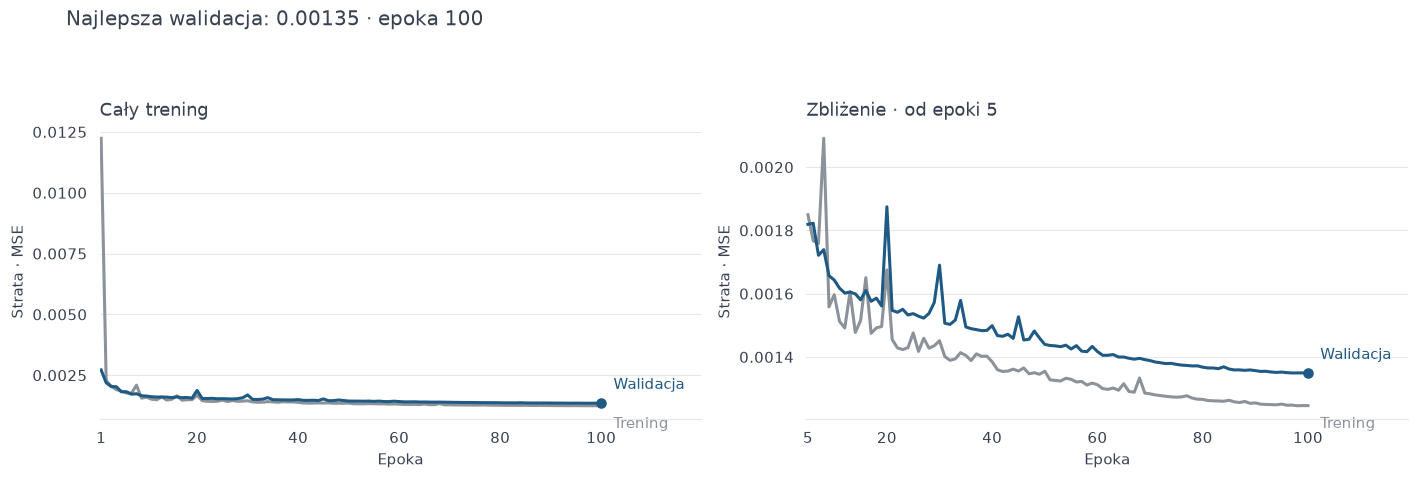

In [39]:
plot_history(history, loss_name=checkpoint["config"].get("loss_name", "MSE"))


Sprawdzamy na wykresie, w których epokach scheduler zmniejszał krok uczenia.

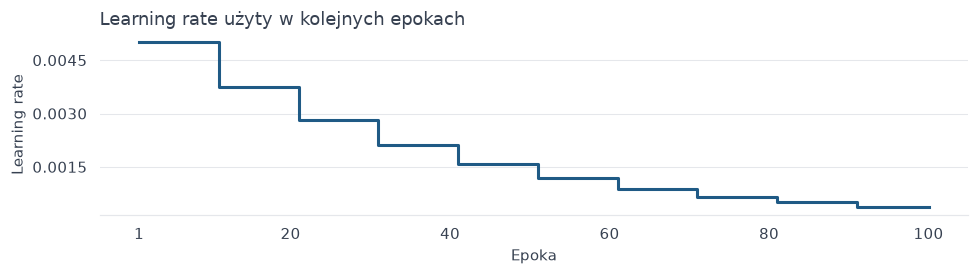

In [40]:
plot_learning_rate(history)


Oceniamy pełną walidację i zapisujemy CSV z nazwą pliku, metrykami obu metod i różnicami, zachowując również zestawienie średnich.

Ocena modelu i bicubic:   0%|          | 0/161 [00:00<?, ?partia/s]

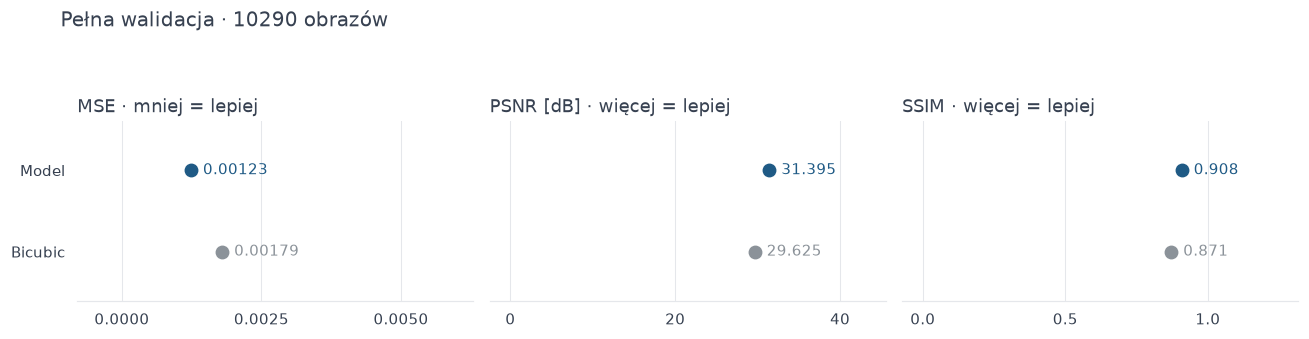

In [41]:
val_per_image = evaluate(best_model, val_loader, DEVICE, show_progress=SHOW_PROGRESS)
val_per_image["filename"] = list(ds_val["filename"])
RESULTS_PATH.mkdir(parents=True, exist_ok=True)
val_per_image.to_csv(RESULTS_PATH / "validation_per_image.csv", index=False)

val_results = summarize_results(val_per_image)
results_frame = pd.DataFrame.from_dict(val_results, orient="index").rename_axis(
    "Metoda"
)
plot_metrics(val_results, title=f"Pełna walidacja · {len(val_dataset)} obrazów")


Sprawdzamy odsetek poprawionych obrazów i rozkład różnic PSNR, aby ocenić, czy poprawa średniej dotyczy większości dzieł.

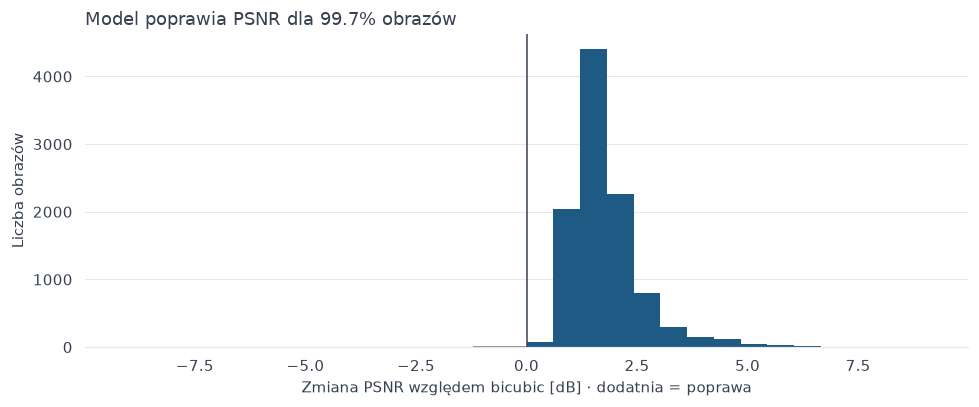

In [42]:
plot_gains(val_per_image)


Oglądamy stałe przykłady walidacyjne po treningu, aby porównywać te same dzieła w kolejnych eksperymentach.

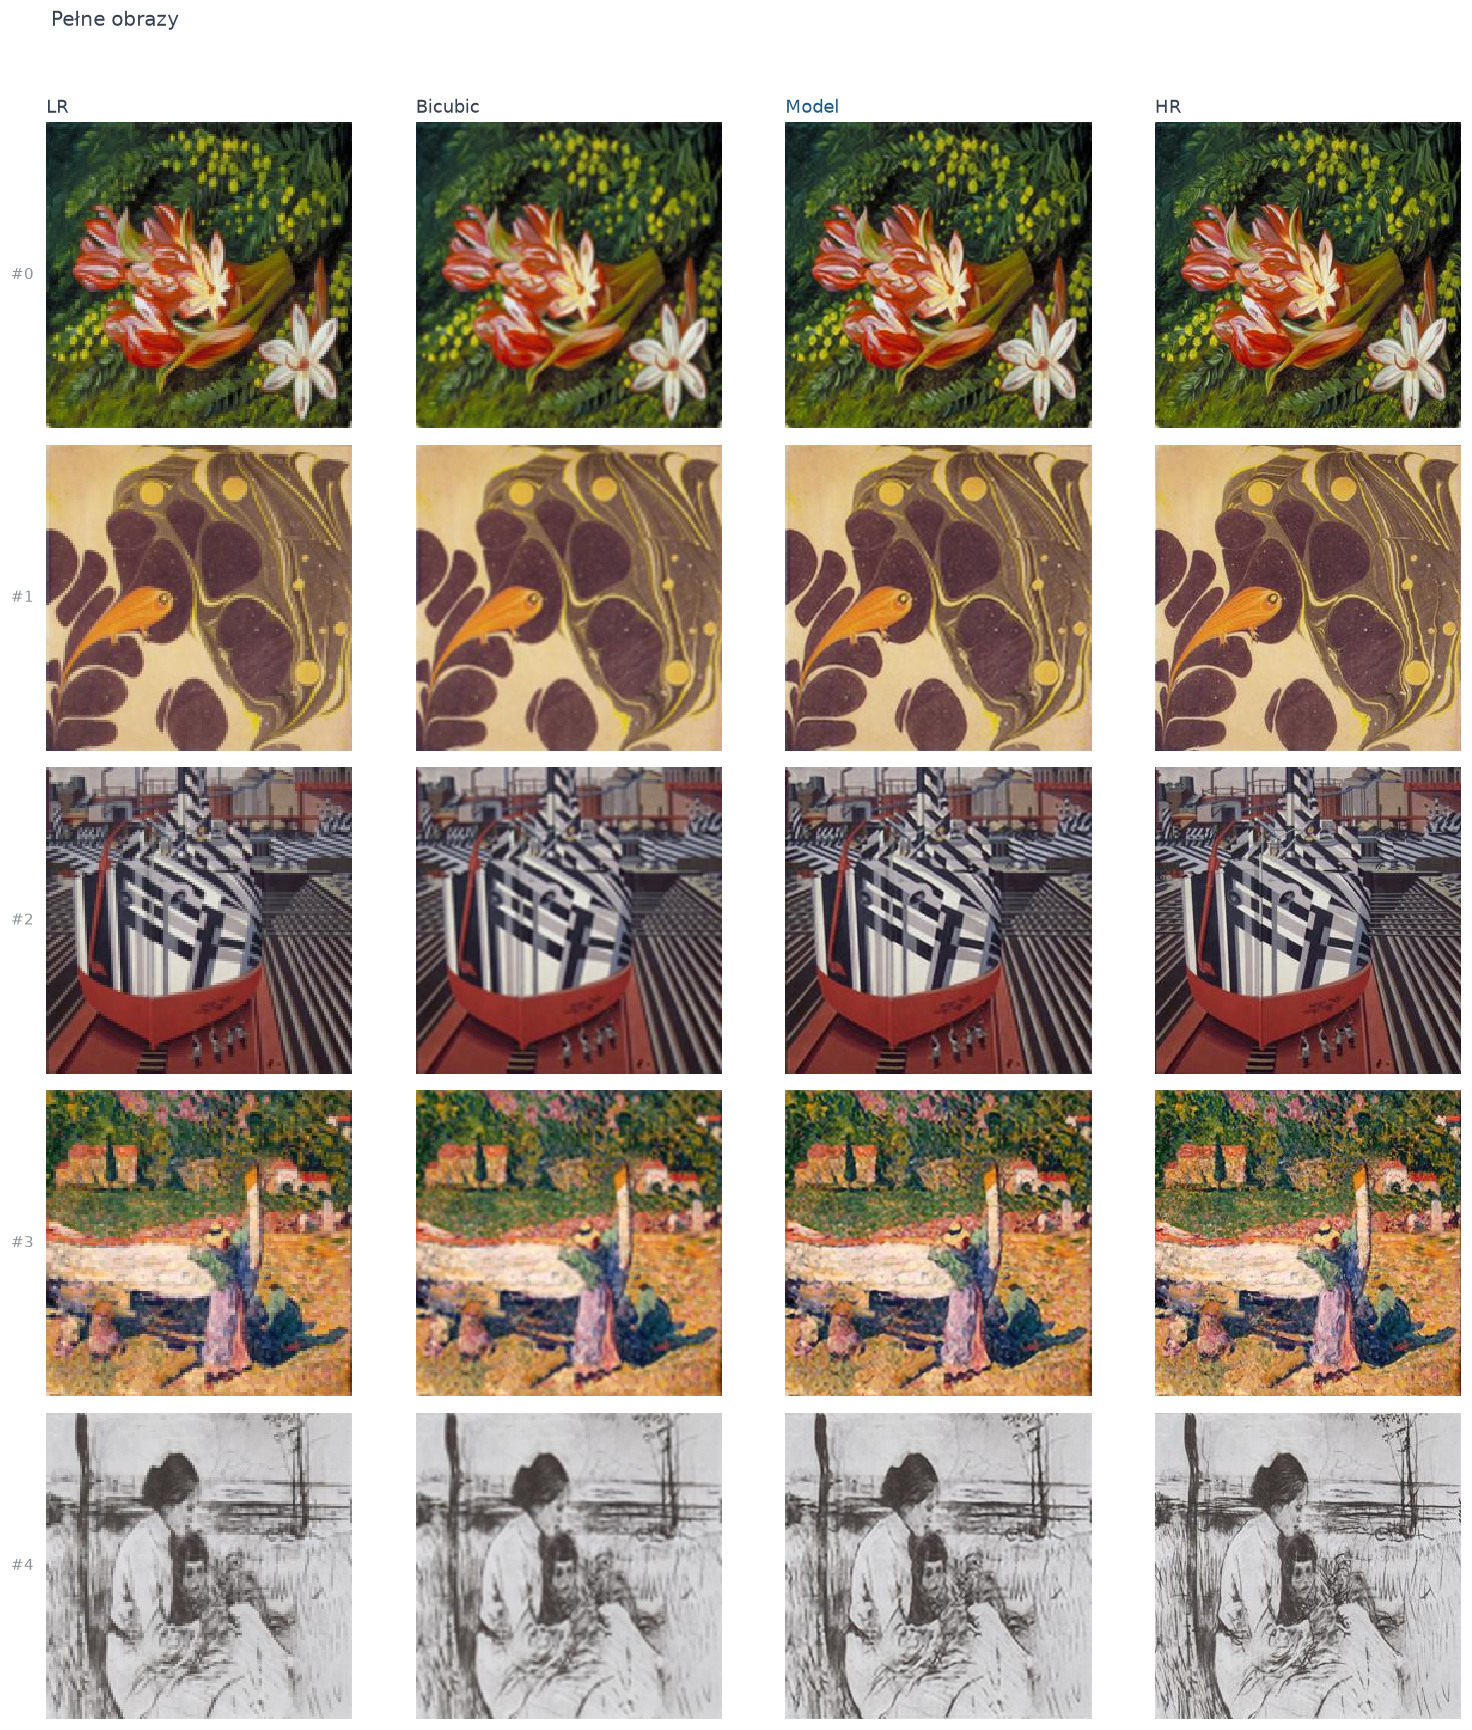

In [43]:
show_predictions(best_model, val_dataset, PREVIEW_INDICES, DEVICE)


Oglądamy te same wyraziste fragmenty bicubic, modelu i HR wybrane według krawędzi obrazu referencyjnego.

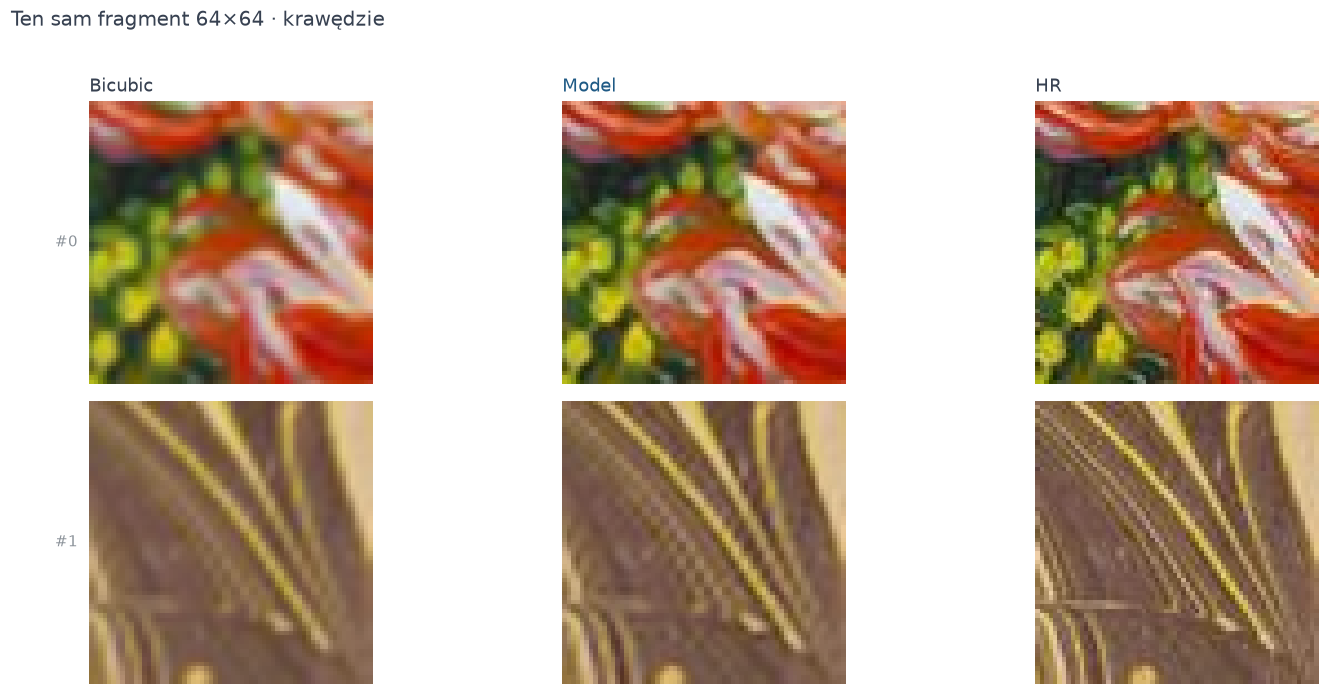

In [44]:
show_predictions(best_model, val_dataset, PREVIEW_INDICES[:2], DEVICE, detail_size=64)


Wybieramy największe i najmniejsze poprawy PSNR względem bicubic oraz pokazujemy małą tabelę z nazwami obrazów.

In [45]:
best_cases = val_per_image.nlargest(CASE_COUNT, "psnr_gain")
worst_cases = val_per_image.nsmallest(CASE_COUNT, "psnr_gain")
best_indices = best_cases["index"].astype(int).tolist()
worst_indices = worst_cases["index"].astype(int).tolist()

case_table = pd.concat(
    [
        best_cases.assign(group="Najlepsze przypadki"),
        worst_cases.assign(group="Najsłabsze przypadki"),
    ]
)
display(case_table[["group", "index", "filename", "psnr_gain"]].round(3))


,group,index,filename,psnr_gain
7905,Najlepsze przypadki,7905,64364.jpg,9.077
2063,Najlepsze przypadki,2063,84122.jpg,8.361
532,Najlepsze przypadki,532,74276.jpg,8.235
1359,Najsłabsze przypadki,1359,92389.jpg,-5.272
5622,Najsłabsze przypadki,5622,103100.jpg,-4.334
2641,Najsłabsze przypadki,2641,46745.jpg,-4.198


Oglądamy wyraziste fragmenty obrazów, na których model uzyskał największy wzrost PSNR względem bicubic.

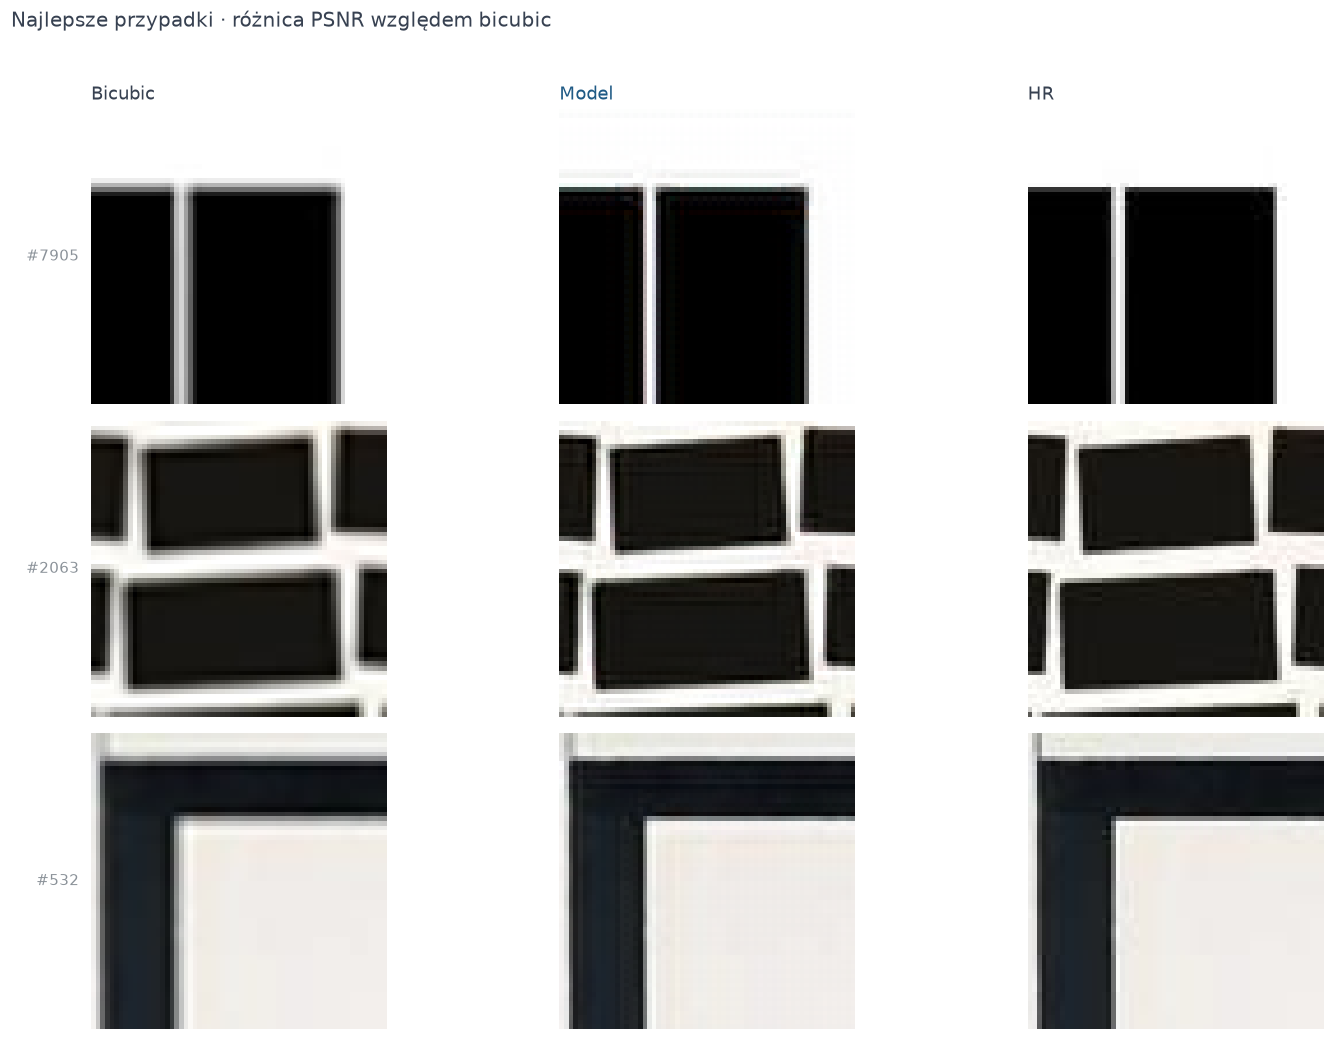

In [46]:
show_predictions(
    best_model,
    val_dataset,
    best_indices,
    DEVICE,
    detail_size=64,
    title="Najlepsze przypadki · różnica PSNR względem bicubic",
)


Oglądamy obrazy z najmniejszą poprawą lub pogorszeniem PSNR, aby szukać powtarzających się słabości modelu.

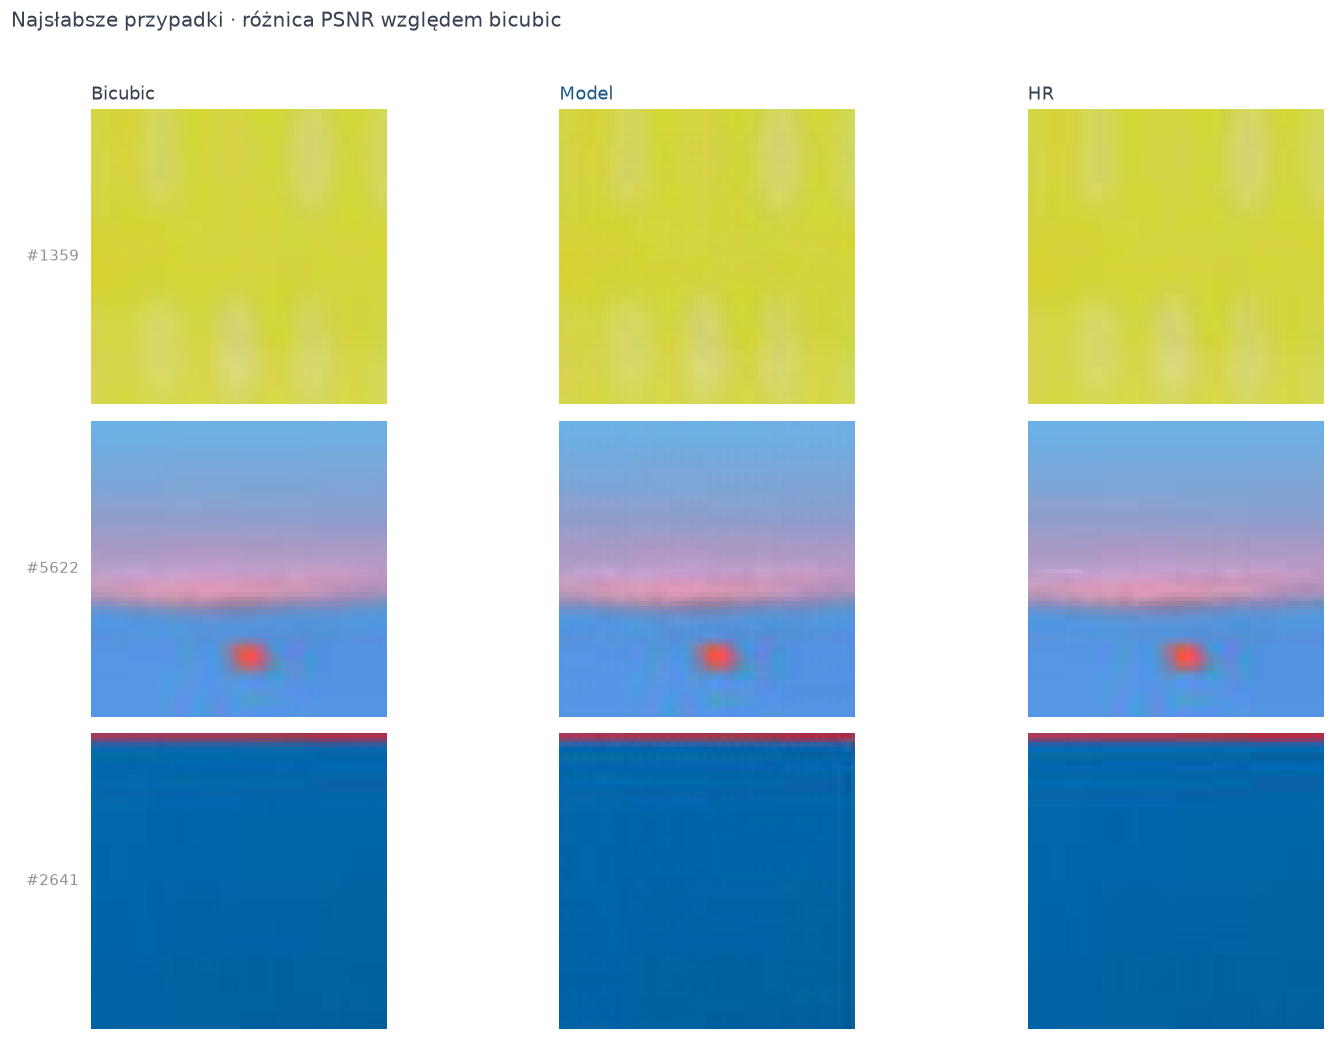

In [47]:
show_predictions(
    best_model,
    val_dataset,
    worst_indices,
    DEVICE,
    detail_size=64,
    title="Najsłabsze przypadki · różnica PSNR względem bicubic",
)


Pokazujemy użycie modelu na oryginale 256×256 jako powiększanie do 512×512 bez referencji HR, więc ten przykład służy tylko ocenie wizualnej.

Powiększanie fragmentami:   0%|          | 0/1 [00:00<?, ?fragment/s]

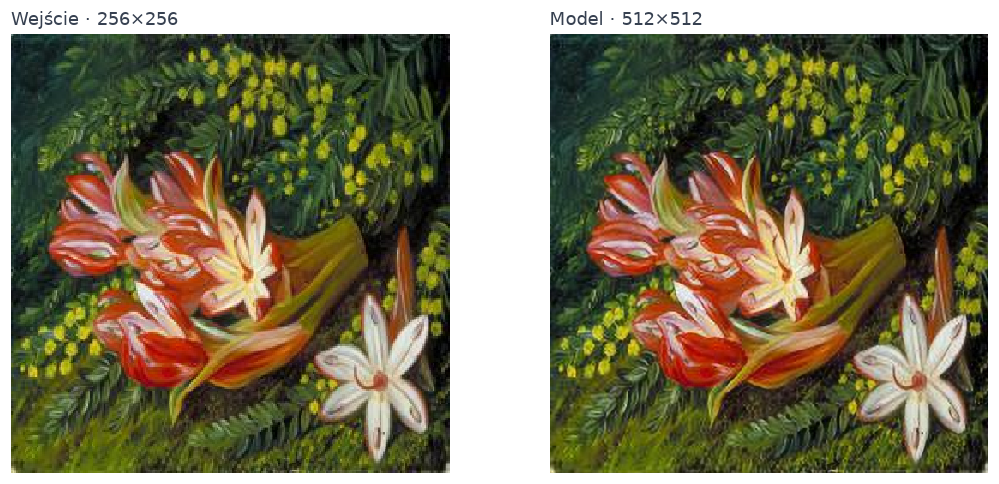

In [48]:
input_image = ds_val[PREVIEW_INDICES[0]]["image"].convert("RGB")
output_image = predict_image(
    best_model,
    input_image,
    DEVICE,
    tile_size=INFERENCE_TILE_SIZE,
    overlap=INFERENCE_OVERLAP,
    show_progress=SHOW_PROGRESS,
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for axis, image, title in zip(
    axes,
    (input_image, output_image),
    (
        f"Wejście · {input_image.width}×{input_image.height}",
        f"Model · {output_image.width}×{output_image.height}",
    ),
):
    axis.imshow(image, interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")

fig.tight_layout()
plt.show()


Końcowy test pozostaje wyłączony, a po jego świadomym włączeniu zapisujemy wyniki poszczególnych obrazów oraz pokazujemy średnie metryki i rozkład poprawy.

In [49]:
if RUN_TEST:
    test_per_image = evaluate(
        best_model, test_loader, DEVICE, show_progress=SHOW_PROGRESS
    )
    test_per_image["filename"] = list(ds_test["filename"])
    RESULTS_PATH.mkdir(parents=True, exist_ok=True)
    test_per_image.to_csv(RESULTS_PATH / "test_per_image.csv", index=False)
    test_results = summarize_results(test_per_image)
    plot_metrics(test_results, title=f"Końcowy test · {len(test_dataset)} obrazów")
    plot_gains(test_per_image)


Powiększamy testowa_fota.jpg najlepszym wczytanym modelem i porównujemy wynik z bicubic wizualnie, ponieważ nie mamy prawdziwej referencji HR dla tego zdjęcia.

Powiększanie fragmentami:   0%|          | 0/6 [00:00<?, ?fragment/s]

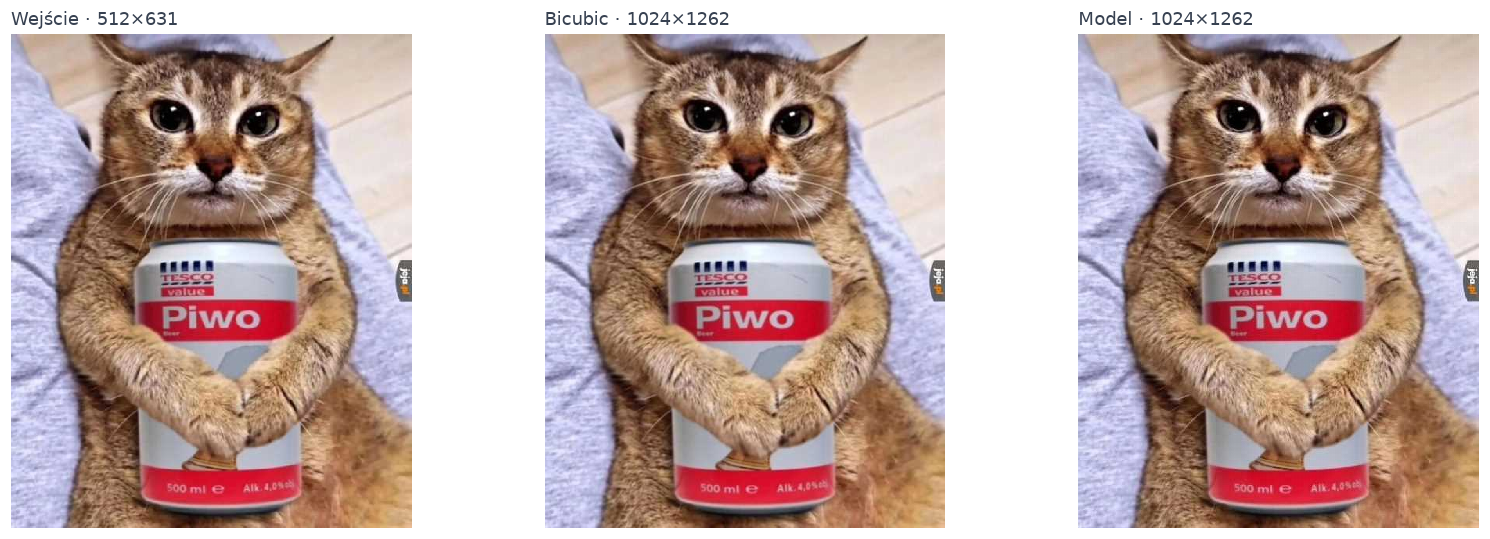

In [51]:
test_image_path = project_root / "notebooks/igoh/testowa_fota_2.jpg"

with Image.open(test_image_path) as image:
    test_image = image.convert("RGB")

test_result = predict_image(
    best_model,
    test_image,
    DEVICE,
    tile_size=INFERENCE_TILE_SIZE,
    overlap=INFERENCE_OVERLAP,
    show_progress=SHOW_PROGRESS,
)
test_bicubic = test_image.resize(test_result.size, Image.Resampling.BICUBIC)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
previews = (
    (test_image, f"Wejście · {test_image.width}×{test_image.height}"),
    (test_bicubic, f"Bicubic · {test_bicubic.width}×{test_bicubic.height}"),
    (test_result, f"Model · {test_result.width}×{test_result.height}"),
)

for axis, (image, title) in zip(axes, previews):
    axis.imshow(image, interpolation="nearest")
    axis.set_title(title)
    axis.axis("off")

fig.tight_layout()
plt.show()
